In [3]:
CONFIG = {

    "SEED": 42,

    "BATCH_SIZE": 64,

    "EPOCHS": 100,

    "LEARNING_RATE": 1e-3,

    "WEIGHT_DECAY": 1e-4,

    "HIDDEN_SIZE": 128,

    "NUM_LAYERS": 2,

    "DROPOUT": 0.3,

    "NUM_CLASSES": 9,

    "INPUT_PATH": "/kaggle/input/notebooks/ssuhaass/01-data-preprocessing-ipynb/processed_data",

    "SAVE_DIR": "/kaggle/working/baseline_results"
}

In [4]:
############################################################
# 2. IMPORT LIBRARIES
############################################################

import random
import time
import joblib
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    cohen_kappa_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from tqdm import tqdm

import warnings
warnings.filterwarnings("ignore")

In [5]:
############################################################
# 3. REPRODUCIBILITY
############################################################

def set_seed(seed):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["SEED"])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", DEVICE)

Device : cuda


In [6]:
############################################################
# 4. LOAD PROCESSED DATA
############################################################

import os
import numpy as np
import joblib

INPUT_PATH = CONFIG["INPUT_PATH"]

# Load processed datasets
train = np.load(os.path.join(INPUT_PATH, "train.npz"))
validation = np.load(os.path.join(INPUT_PATH, "validation.npz"))
test = np.load(os.path.join(INPUT_PATH, "test.npz"))

X_train = train["X"]
y_train = train["y"]

X_val = validation["X"]
y_val = validation["y"]

X_test = test["X"]
y_test = test["y"]

# Load preprocessing objects
scaler = joblib.load(os.path.join(INPUT_PATH, "scaler.pkl"))
pca = joblib.load(os.path.join(INPUT_PATH, "pca.pkl"))

print("="*60)
print("Training   :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Testing    :", X_test.shape, y_test.shape)
print("="*60)

Training   : (2138, 9, 9, 30) (2138,)
Validation : (2138, 9, 9, 30) (2138,)
Testing    : (38500, 9, 9, 30) (38500,)


In [7]:
############################################################
# 5. PYTORCH DATASET
############################################################

from torch.utils.data import Dataset

class HSIDataset(Dataset):

    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [8]:
############################################################
# 6. DATALOADERS
############################################################

from torch.utils.data import DataLoader

train_dataset = HSIDataset(X_train, y_train)
val_dataset = HSIDataset(X_val, y_val)
test_dataset = HSIDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["BATCH_SIZE"],
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["BATCH_SIZE"],
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["BATCH_SIZE"],
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("="*60)
print(f"Train Samples      : {len(train_dataset)}")
print(f"Validation Samples : {len(val_dataset)}")
print(f"Test Samples       : {len(test_dataset)}")
print("-"*60)
print(f"Train Batches      : {len(train_loader)}")
print(f"Validation Batches : {len(val_loader)}")
print(f"Test Batches       : {len(test_loader)}")
print("="*60)

Train Samples      : 2138
Validation Samples : 2138
Test Samples       : 38500
------------------------------------------------------------
Train Batches      : 34
Validation Batches : 34
Test Batches       : 602


In [9]:
############################################################
# 7. MODEL CONFIGURATION
############################################################

PATCH_SIZE = X_train.shape[1]
PCA_COMPONENTS = X_train.shape[-1]

SEQUENCE_LENGTH = PCA_COMPONENTS
INPUT_SIZE = PATCH_SIZE * PATCH_SIZE

print("="*60)
print("Patch Size       :", PATCH_SIZE)
print("PCA Components   :", PCA_COMPONENTS)
print("Sequence Length  :", SEQUENCE_LENGTH)
print("Input Size       :", INPUT_SIZE)
print("="*60)

Patch Size       : 9
PCA Components   : 30
Sequence Length  : 30
Input Size       : 81


In [10]:
############################################################
# 8. PCA + LSTM MODEL
############################################################

class PCALSTM(nn.Module):

    def __init__(self):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=INPUT_SIZE,
            hidden_size=CONFIG["HIDDEN_SIZE"],
            num_layers=CONFIG["NUM_LAYERS"],
            batch_first=True,
            dropout=CONFIG["DROPOUT"]
        )

        self.dropout = nn.Dropout(CONFIG["DROPOUT"])

        self.classifier = nn.Linear(
            CONFIG["HIDDEN_SIZE"],
            CONFIG["NUM_CLASSES"]
        )

    def forward(self, x):

        B = x.size(0)

        # (B,9,9,30)
        x = x.reshape(B, PATCH_SIZE * PATCH_SIZE, PCA_COMPONENTS)

        # (B,81,30)
        x = x.permute(0,2,1)

        # (B,30,81)

        output, _ = self.lstm(x)

        output = output[:, -1, :]

        output = self.dropout(output)

        output = self.classifier(output)

        return output

In [11]:
############################################################
# CREATE MODEL
############################################################

model = PCALSTM().to(DEVICE)

print(model)

############################################################
# PARAMETER COUNT
############################################################

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("="*60)
print(f"Total Parameters      : {total_params:,}")
print(f"Trainable Parameters  : {trainable_params:,}")
print("="*60)

PCALSTM(
  (lstm): LSTM(81, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=9, bias=True)
)
Total Parameters      : 241,289
Trainable Parameters  : 241,289


In [12]:
############################################################
# 9. LOSS & OPTIMIZER
############################################################

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(

    model.parameters(),

    lr=CONFIG["LEARNING_RATE"],

    weight_decay=CONFIG["WEIGHT_DECAY"]

)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="max",

    factor=0.5,

    patience=5
)

In [13]:
############################################################
# 10. TRAINING FUNCTION
############################################################

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for X, y in progress:

        X = X.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(X)

        loss = criterion(outputs, y)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * X.size(0)

        _, predicted = outputs.max(1)

        total += y.size(0)

        correct += predicted.eq(y).sum().item()

        progress.set_postfix(
            Loss=f"{loss.item():.4f}",
            Acc=f"{100*correct/total:.2f}%"
        )

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [14]:
############################################################
# 11. VALIDATION FUNCTION
############################################################

def validate_one_epoch(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        progress = tqdm(loader, desc="Validation", leave=False)

        for X, y in progress:

            X = X.to(DEVICE)
            y = y.to(DEVICE)

            outputs = model(X)

            loss = criterion(outputs, y)

            running_loss += loss.item() * X.size(0)

            _, predicted = outputs.max(1)

            total += y.size(0)

            correct += predicted.eq(y).sum().item()

            progress.set_postfix(
                Loss=f"{loss.item():.4f}",
                Acc=f"{100*correct/total:.2f}%"
            )

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [15]:
############################################################
# 12. TRAIN MODEL
############################################################

os.makedirs(CONFIG["SAVE_DIR"], exist_ok=True)

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0

start_time = time.time()

for epoch in range(CONFIG["EPOCHS"]):

    print(f"\nEpoch {epoch+1}/{CONFIG['EPOCHS']}")
    print("-"*60)

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)

    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Val Acc    : {val_acc:.2f}%")

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            os.path.join(CONFIG["SAVE_DIR"], "best_model.pth")
        )

        print("Best model saved.")

training_time = time.time() - start_time

print("="*60)
print(f"Training Completed")
print(f"Best Validation Accuracy : {best_val_acc:.2f}%")
print(f"Training Time : {training_time/60:.2f} minutes")
print("="*60)


Epoch 1/100
------------------------------------------------------------


Train Loss : 1.8816
Train Acc  : 41.67%
Val Loss   : 1.7417
Val Acc    : 43.59%
Best model saved.

Epoch 2/100
------------------------------------------------------------


Train Loss : 1.7266
Train Acc  : 43.59%
Val Loss   : 1.7014
Val Acc    : 43.59%

Epoch 3/100
------------------------------------------------------------


Train Loss : 1.6220
Train Acc  : 45.18%
Val Loss   : 1.5798
Val Acc    : 47.80%
Best model saved.

Epoch 4/100
------------------------------------------------------------


Train Loss : 1.4340
Train Acc  : 51.92%
Val Loss   : 1.4221
Val Acc    : 52.90%
Best model saved.

Epoch 5/100
------------------------------------------------------------


...

Train Loss : 0.0026
Train Acc  : 100.00%
Val Loss   : 0.8547
Val Acc    : 82.23%

Epoch 97/100
------------------------------------------------------------


Train Loss : 0.0025
Train Acc  : 100.00%
Val Loss   : 0.8547
Val Acc    : 82.23%

Epoch 98/100
------------------------------------------------------------


Train Loss : 0.0026
Train Acc  : 100.00%
Val Loss   : 0.8547
Val Acc    : 82.23%

Epoch 99/100
------------------------------------------------------------


Train Loss : 0.0024
Train Acc  : 100.00%
Val Loss   : 0.8547
Val Acc    : 82.23%

Epoch 100/100
------------------------------------------------------------


Train Loss : 0.0027
Train Acc  : 100.00%
Val Loss   : 0.8547
Val Acc    : 82.23%
Training Completed
Best Validation Accuracy : 82.65%
Training Time : 0.77 minutes


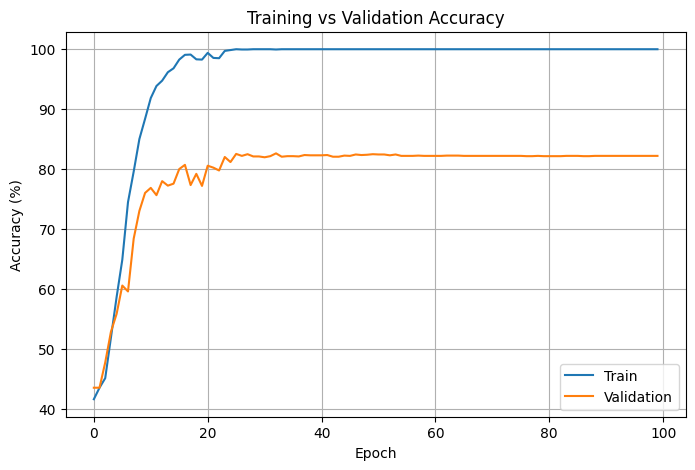

In [16]:
############################################################
# 13. LEARNING CURVES
############################################################

plt.figure(figsize=(8,5))

plt.plot(history["train_acc"], label="Train")

plt.plot(history["val_acc"], label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid(True)

plt.show()

In [17]:
############################################################
# 14. LOAD BEST MODEL
############################################################

best_model_path = os.path.join(CONFIG["SAVE_DIR"], "best_model.pth")

model.load_state_dict(torch.load(best_model_path))

model.eval()

print("Best model loaded successfully.")

Best model loaded successfully.


In [18]:
############################################################
# 15. TEST FUNCTION
############################################################

def evaluate_model(model, loader):

    model.eval()

    predictions = []
    targets = []

    start = time.time()

    with torch.no_grad():

        for X, y in tqdm(loader, desc="Testing"):

            X = X.to(DEVICE)
            y = y.to(DEVICE)

            outputs = model(X)

            _, pred = torch.max(outputs, 1)

            predictions.extend(pred.cpu().numpy())
            targets.extend(y.cpu().numpy())

    inference_time = time.time() - start

    return np.array(targets), np.array(predictions), inference_time

In [19]:
############################################################
# 16. TEST MODEL
############################################################

y_true, y_pred, inference_time = evaluate_model(
    model,
    test_loader
)

Testing: 100%|██████████| 602/602 [00:01<00:00, 386.88it/s]


In [20]:
############################################################
# 17. PERFORMANCE METRICS
############################################################

oa = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="macro"
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro"
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

kappa = cohen_kappa_score(
    y_true,
    y_pred
)

cm = confusion_matrix(
    y_true,
    y_pred
)

class_acc = cm.diagonal() / cm.sum(axis=1)

aa = np.mean(class_acc)

print("="*60)

print(f"Overall Accuracy : {oa*100:.2f}%")

print(f"Average Accuracy : {aa*100:.2f}%")

print(f"Kappa            : {kappa:.4f}")

print(f"Precision        : {precision:.4f}")

print(f"Recall           : {recall:.4f}")

print(f"F1 Score         : {f1:.4f}")

print(f"Inference Time   : {inference_time:.2f} sec")

print("="*60)

Overall Accuracy : 82.86%
Average Accuracy : 77.69%
Kappa            : 0.7725
Precision        : 0.7807
Recall           : 0.7769
F1 Score         : 0.7776
Inference Time   : 1.56 sec


In [21]:
############################################################
# 18. CLASSIFICATION REPORT
############################################################

print(
    classification_report(
        y_true,
        y_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.7896    0.7429    0.7656      5967
           1     0.9216    0.9312    0.9264     16785
           2     0.6241    0.6908    0.6558      1889
           3     0.8792    0.8600    0.8695      2758
           4     0.8262    0.7655    0.7947      1211
           5     0.6738    0.7557    0.7124      4527
           6     0.7182    0.7266    0.7224      1196
           7     0.7829    0.6693    0.7217      3314
           8     0.8110    0.8499    0.8300       853

    accuracy                         0.8286     38500
   macro avg     0.7807    0.7769    0.7776     38500
weighted avg     0.8307    0.8286    0.8287     38500



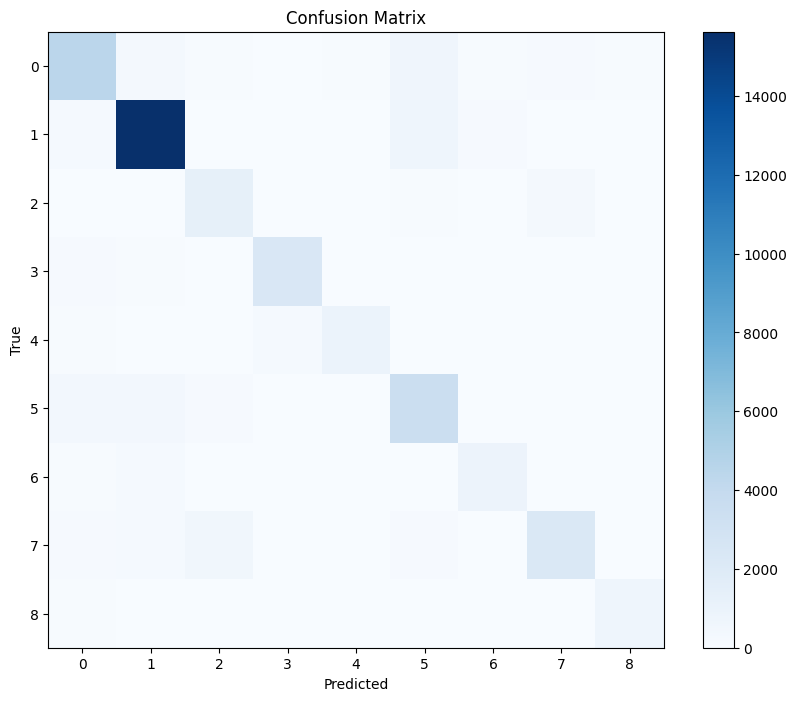

In [22]:
############################################################
# 19. CONFUSION MATRIX
############################################################

plt.figure(figsize=(10,8))

plt.imshow(cm, cmap="Blues")

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("True")

plt.colorbar()

plt.show()

In [23]:
############################################################
# 20. SAVE METRICS
############################################################

import json

results = {

    "Overall Accuracy": float(oa),

    "Average Accuracy": float(aa),

    "Kappa": float(kappa),

    "Precision": float(precision),

    "Recall": float(recall),

    "F1": float(f1),

    "Training Time (min)": float(training_time / 60),

    "Inference Time (sec)": float(inference_time),

    "Parameters": int(trainable_params)
}

os.makedirs(CONFIG["SAVE_DIR"], exist_ok=True)

with open(
    os.path.join(CONFIG["SAVE_DIR"], "metrics.json"),
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )

print("Metrics saved successfully.")

Metrics saved successfully.
